# Import Data and PreProcessing

In [ ]:
pip install stable_baselines3

In [ ]:
import pandas as pd
import numpy as np
import gymnasium as gym
from gymnasium import spaces
import matplotlib.dates as mdates
import torch
from stable_baselines3 import SAC
from stable_baselines3.common.callbacks import EvalCallback
from stable_baselines3.common.monitor import Monitor
import time
from datetime import datetime
from google.colab import drive

import matplotlib.pyplot as plt


In [14]:
merit_order = pd.read_csv("/content/france_smoothed_merit_order_matrix.csv")
actual_generation_mix = pd.read_csv("/content/france_actual_generation_mix.csv")
outages = pd.read_csv("/content/france_comprehensive_outages_2020_2026.csv")
DAM_load_forecast = pd.read_csv("/content/france_day_ahead_load_forecast.csv")
DAM_prices = pd.read_csv("/content/france_day_ahead_prices.csv")
hourly_storage_dispatch = pd.read_csv("/content/france_gross_hourly_storage_dispatch.csv")
wind_solar_forecast = pd.read_csv("/content/france_wind_solar_forecast.csv")

dfs = [merit_order, actual_generation_mix, outages, DAM_load_forecast, DAM_prices, hourly_storage_dispatch, wind_solar_forecast]

for _ in dfs :
  print("//////")
  print(_.head(10))


//////
                  Unnamed: 0  Price_at_0MW  Price_at_1000MW  Price_at_2000MW  \
0  2020-01-01 00:00:00+00:00           0.0              0.0         0.000000   
1  2020-01-01 01:00:00+00:00           0.0              0.0         0.000000   
2  2020-01-01 02:00:00+00:00           0.0              0.0         0.000000   
3  2020-01-01 03:00:00+00:00           0.0              0.0         0.000000   
4  2020-01-01 04:00:00+00:00           0.0              0.0         0.000000   
5  2020-01-01 05:00:00+00:00           0.0              0.0         0.000000   
6  2020-01-01 06:00:00+00:00           0.0              0.0         0.000000   
7  2020-01-01 07:00:00+00:00           0.0              0.0         0.362613   
8  2020-01-01 08:00:00+00:00           0.0              0.0         0.003231   
9  2020-01-01 09:00:00+00:00           0.0              0.0         0.000000   

   Price_at_3000MW  Price_at_4000MW  Price_at_5000MW  Price_at_6000MW  \
0         0.000000         1.285512    

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:

def prepare_rl_dataset(dfs_dict):
    """
    Cleans, merges, and engineers the state space features from the raw DataFrames.
    dfs_dict: dictionary of raw DataFrames.
    """
    clean_dfs = []

    for name, df in dfs_dict.items():
        # Standardize the datetime column name
        time_col = 'Unnamed: 0' if 'Unnamed: 0' in df.columns else 'Datetime'

        # Convert to datetime and force to UTC to standardize the index
        df['Datetime_UTC'] = pd.to_datetime(df[time_col], utc=True)
        df = df.set_index('Datetime_UTC')
        df = df.drop(columns=[time_col])
        clean_dfs.append(df)

    # Merge everything on the standardized UTC index
    master_df = pd.concat(clean_dfs, axis=1, join='inner')

    # Calculate Forecasted Residual Load (RL_t^f)
    master_df['RL_forecast'] = master_df['Forecasted_Load_MW'] - master_df['Total_W_t']

    # Min-Max normalize RL_forecast (to keep neural network inputs stable)
    rl_min = master_df['RL_forecast'].min()
    rl_max = master_df['RL_forecast'].max()
    master_df['RL_norm'] = (master_df['RL_forecast'] - rl_min) / (rl_max - rl_min)

    # Scale-Invariant Relative Price Position
    rolling_24 = master_df['Price_EUR_MWh'].rolling(window=24, min_periods=24)
    price_min_24 = rolling_24.min()
    price_max_24 = rolling_24.max()
    epsilon = 1e-6 # Prevent division by zero

    master_df['Price_Pos'] = (master_df['Price_EUR_MWh'] - price_min_24) / (price_max_24 - price_min_24 + epsilon)

    # Create 24-hour Historical Price Lags
    for i in range(1, 25):
        # We normalize the lags against the rolling 24h max to keep them scale-invariant too
        master_df[f'Price_Lag_{i}'] = master_df['Price_EUR_MWh'].shift(i) / (price_max_24 + epsilon)

    # Create 24-hour Future Forecast Leads for Residual Load
    for i in range(1, 25):
        # We shift backwards (-i) to pull tomorrow's forecast into today's state
        # Because 'RL_norm' is ALREADY min-max normalized, the leads are perfectly safe
        master_df[f'RL_Lead_{i}'] = master_df['RL_norm'].shift(-i)

    # Temporal Features (Sine/Cosine for continuous cyclicality)
    hour = master_df.index.hour
    day_of_week = master_df.index.dayofweek

    master_df['sin_hour'] = np.sin(2 * np.pi * hour / 24)
    master_df['cos_hour'] = np.cos(2 * np.pi * hour / 24)
    master_df['sin_day'] = np.sin(2 * np.pi * day_of_week / 7)
    master_df['cos_day'] = np.cos(2 * np.pi * day_of_week / 7)

    # Drop NaNs created by the 24-hour rolling windows/shifts
    master_df = master_df.dropna()

    return master_df

# Create a dictionary of the dataframes to pass to the function
raw_data = {
    'merit': merit_order,
    'load': DAM_load_forecast,
    'prices': DAM_prices,
    'vre': wind_solar_forecast
}

rl_dataset = prepare_rl_dataset(raw_data)

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Setting up gymnasium environment


In [ ]:
drive.mount('/content/drive')
save_path = '/content/drive/MyDrive/Battery_RL_Model/'

# ==========================================
# CHRONOLOGICAL SPLIT (NO SCALING)
# ==========================================
train_df = rl_dataset.loc['2020-01-01':'2023-12-31']
val_df = rl_dataset.loc['2024-01-01':'2024-12-31']
test_df = rl_dataset.loc['2025-01-01':'2026-12-31']

# ==========================================
# GYMNASIUM ENVIRONMENT
# ==========================================
class StrategicBatteryEnv(gym.Env):
    metadata = {'render_modes': ['human']}

    def __init__(self, rl_dataset: pd.DataFrame, max_mw_capacity: float, max_mwh_energy: float):
        super().__init__()
        self.df = rl_dataset
        self.max_mw = max_mw_capacity
        self.max_mwh = max_mwh_energy
        self.current_step = 0
        self.max_steps = len(self.df) - 1
        self.soc = 0.5

        self.action_space = spaces.Box(low=-1.0, high=1.0, shape=(1,), dtype=np.float32)
        self.observation_space = spaces.Box(low=-1.0, high=1.0, shape=(55,), dtype=np.float32)

    def _get_obs(self):
        row = self.df.iloc[self.current_step]
        lags = [row[f'Price_Lag_{i}'] for i in range(1, 25)]
        leads = [row[f'RL_Lead_{i}'] for i in range(1, 25)] # <--- Get the future forecasts

        obs = [self.soc, row['RL_norm'], row['Price_Pos']] + lags + leads + [
            row['sin_hour'], row['cos_hour'], row['sin_day'], row['cos_day']
        ]
        return np.array(obs, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0
        self.soc = 0.5
        return self._get_obs(), {}

    def step(self, action):
        row = self.df.iloc[self.current_step]
        raw_action = action[0]

        # MECHANICAL DEADBAND: Ignore noise. If the requested action is less than 2%, do nothing.
        if abs(raw_action) < 0.01:
            raw_action = 0.0

        eta = np.sqrt(0.85)
        c_max = self.max_mw
        e_max = self.max_mwh
        e_t = self.soc * e_max
        p_req = raw_action * c_max

        if p_req > 0:
            p_dispatch = min(p_req, c_max, e_t * eta)
        else:
            p_dispatch = max(p_req, -c_max, -(e_max - e_t) / eta)

        if p_dispatch > 0:
            e_next = e_t - (p_dispatch / eta)
        else:
            e_next = e_t - (p_dispatch * eta)

        # Update internal state with a 0.01% hourly self-discharge leak
        self.soc = (e_next / e_max) * 0.9999

        # Hard clip to ensure it never physically breaks bounds due to floating point math
        self.soc = np.clip(self.soc, 0.0, 1.0)

        residual_load = row['RL_forecast']
        shifted_demand = residual_load - p_dispatch
        capacity_grid = np.arange(0, 91000, 1000)
        price_curve = row.loc['Price_at_0MW':'Price_at_90000MW'].values.astype(float)
        shifted_demand_clipped = np.clip(shifted_demand, 0, 90000)
        p_star = np.interp(shifted_demand_clipped, capacity_grid, price_curve)

        c_base_penalty = 0.5
        alpha = 1.0
        beta = 0.5
        throughput = abs(p_dispatch)
        kappa = c_base_penalty * throughput + np.exp(alpha * abs(self.soc - 0.5)) * beta * throughput

        # Static divisor for the static 3000MW 
        reward = ((p_star * p_dispatch) - kappa) / 30000.0

        self.current_step += 1
        terminated = self.current_step >= self.max_steps

        info = {'endogenous_price': p_star, 'realized_dispatch': p_dispatch, 'degradation_cost': kappa}
        return self._get_obs(), reward, terminated, False, info

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ==========================================
# INITIALIZE AND TRAIN SAC AGENT
# ==========================================
BATTERY_MW = 3000.0
BATTERY_MWH = 6000.0

env_train = Monitor(StrategicBatteryEnv(train_df, BATTERY_MW, BATTERY_MWH))
env_val = Monitor(StrategicBatteryEnv(val_df, BATTERY_MW, BATTERY_MWH))

eval_callback = EvalCallback(
    env_val,
    best_model_save_path=save_path,
    log_path=save_path,
    eval_freq=10000,
    deterministic=True,
    render=False
)

model = SAC(
    "MlpPolicy",
    env_train,
    policy_kwargs=dict(activation_fn=torch.nn.ReLU, net_arch=dict(pi=[256, 256, 256], qf=[256, 256, 256])),
    learning_rate=3e-4,
    buffer_size=100000,
    batch_size=256,
    ent_coef='auto',
    gamma=0.99,
    verbose=1
)

TOTAL_TIMESTEPS = 200000
print("Starting SAC training loop. This may take a while depending on hardware...")
model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=eval_callback)
print(f"Training complete! Best models safely stored in {save_path}")

Using cpu device
Wrapping the env in a DummyVecEnv.
Starting SAC training loop. This may take a while depending on your hardware...
Eval num_timesteps=10000, episode_reward=66.38 +/- 0.00
Episode length: 8780.00 +/- 0.00
---------------------------------
| eval/              |          |
|    mean_ep_length  | 8.78e+03 |
|    mean_reward     | 66.4     |
| time/              |          |
|    total_timesteps | 10000    |
| train/             |          |
|    actor_loss      | -4.3     |
|    critic_loss     | 0.0227   |
|    ent_coef        | 0.055    |
|    ent_coef_loss   | -3.64    |
|    learning_rate   | 0.0003   |
|    n_updates       | 9899     |
---------------------------------
New best mean reward!
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 3.53e+03 |
|    ep_rew_mean     | -85.7    |
| time/              |          |
|    episodes        | 4        |
|    fps             | 19       |
|    time_elapsed    | 735      |
|    tota

Evaluating agent on the 2025-2026 Test Set...
Evaluation Complete.


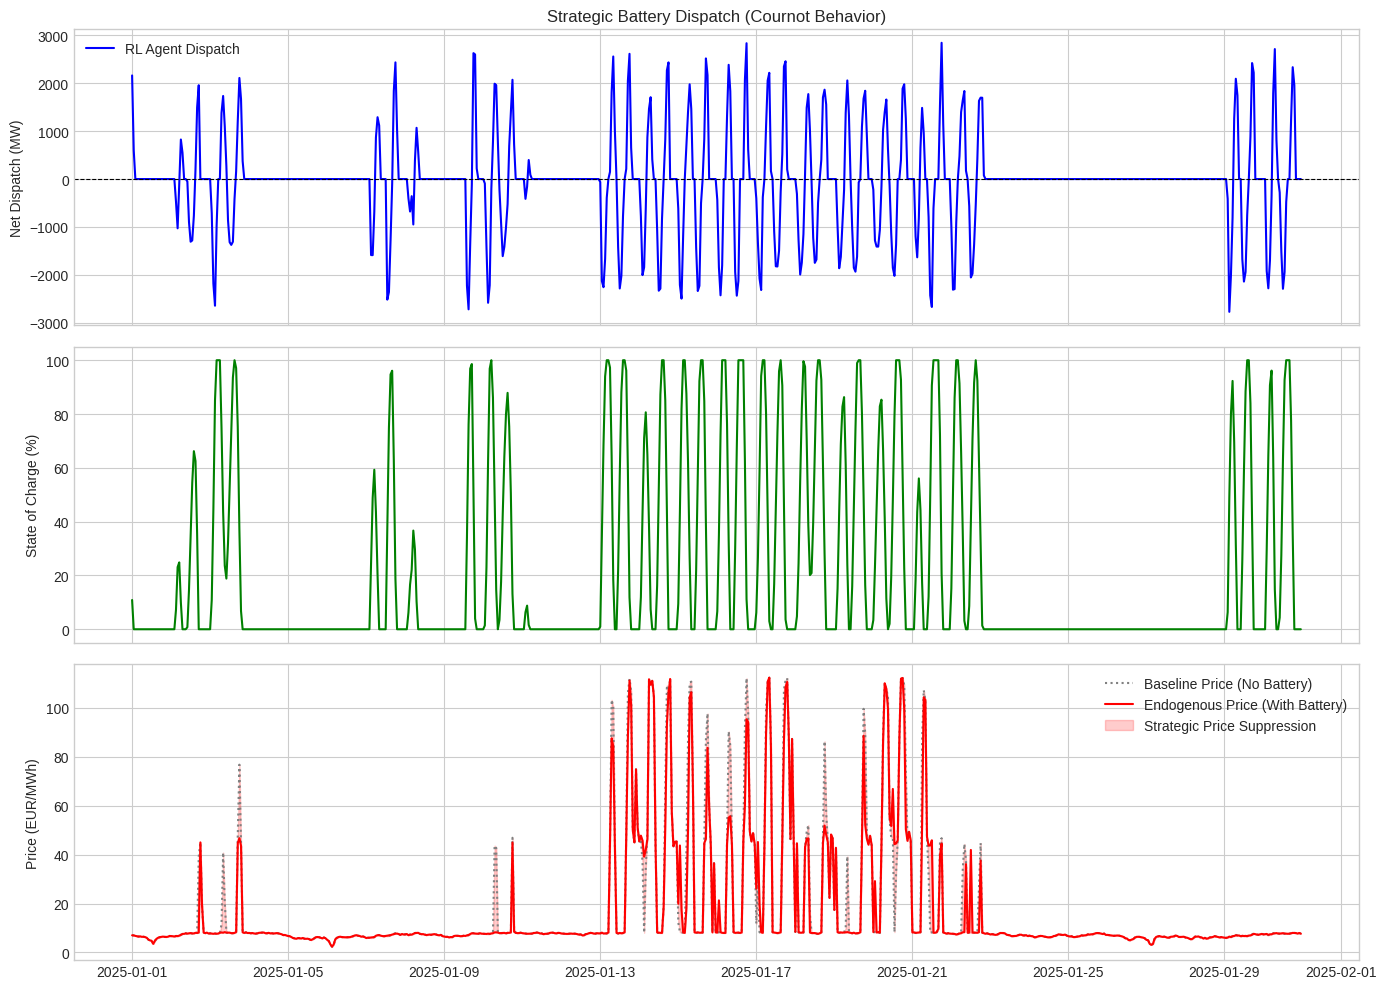

In [ ]:


def evaluate_and_plot(model_path, test_env, test_df):
    """
    Loads the trained SAC agent and evaluates it on the test set,
    extracting the strategic markup and dispatch behavior.
    """
    # Load the best performing model
    trained_model = SAC.load(model_path)

    # Prepare lists to store the simulation results
    results = {
        'Datetime_UTC': [],
        'Agent_Dispatch_MW': [],
        'SoC': [],
        'Baseline_Price_EUR': [],
        'Endogenous_Price_EUR': [],
        'Strategic_Markup_EUR': []
    }

    obs, info = test_env.reset()
    done = False

    print("Evaluating agent on the 2025-2026 Test Set...")

    while not done:
        # The Agent selects an action based on the state
        action, _states = trained_model.predict(obs, deterministic=True)

        # Extract current step data before the environment advances
        current_step_idx = test_env.unwrapped.current_step
        current_row = test_df.iloc[current_step_idx]
        current_datetime = test_df.index[current_step_idx]

        # Step the environment
        obs, reward, terminated, truncated, info = test_env.step(action)
        done = terminated or truncated

        # Calculate the Baseline Price (Perfect Competition)
        # This is the price if the battery injected 0 MW (no market power exercised)
        capacity_grid = np.arange(0, 91000, 1000)
        price_curve = current_row.loc['Price_at_0MW':'Price_at_90000MW'].values.astype(float)

        baseline_demand = np.clip(current_row['RL_forecast'], 0, 90000)
        baseline_price = np.interp(baseline_demand, capacity_grid, price_curve)

        # Store the data
        endogenous_price = info['endogenous_price']

        results['Datetime_UTC'].append(current_datetime)
        results['Agent_Dispatch_MW'].append(info['realized_dispatch'])
        results['SoC'].append(test_env.unwrapped.soc)
        results['Baseline_Price_EUR'].append(baseline_price)
        results['Endogenous_Price_EUR'].append(endogenous_price)
        results['Strategic_Markup_EUR'].append(endogenous_price - baseline_price)

    # Convert results to DataFrame
    eval_df = pd.DataFrame(results).set_index('Datetime_UTC')
    print("Evaluation Complete.")

    # ---------------------------------------------------------
    # PLOTTING THE STRATEGIC BEHAVIOR
    # ---------------------------------------------------------
    # Let's plot a specific volatile week in 2025 as a sample
    sample_week = eval_df.loc['2025-01-01':'2025-01-30']

    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

    # Plot 1: Battery Dispatch
    axes[0].plot(sample_week.index, sample_week['Agent_Dispatch_MW'], color='blue', label='RL Agent Dispatch')
    axes[0].axhline(0, color='black', linestyle='--', linewidth=0.8)
    axes[0].set_ylabel('Net Dispatch (MW)')
    axes[0].set_title('Strategic Battery Dispatch (Cournot Behavior)')
    axes[0].legend()

    # Plot 2: State of Charge
    axes[1].plot(sample_week.index, sample_week['SoC'] * 100, color='green')
    axes[1].set_ylabel('State of Charge (%)')

    # Plot 3: The Price Impact (Strategic Markup)
    axes[2].plot(sample_week.index, sample_week['Baseline_Price_EUR'], color='gray', linestyle=':', label='Baseline Price (No Battery)')
    axes[2].plot(sample_week.index, sample_week['Endogenous_Price_EUR'], color='red', label='Endogenous Price (With Battery)')
    axes[2].fill_between(sample_week.index, sample_week['Baseline_Price_EUR'], sample_week['Endogenous_Price_EUR'], color='red', alpha=0.2, label='Strategic Price Suppression')
    axes[2].set_ylabel('Price (EUR/MWh)')
    axes[2].legend()

    plt.tight_layout()
    plt.show()

    return eval_df

# To run this after training completes:
test_env = StrategicBatteryEnv(test_df, BATTERY_MW, BATTERY_MWH)
final_results_df = evaluate_and_plot('/content/drive/MyDrive/Battery_RL_Model/best_model.zip', test_env, test_df)
# Save  final output for paper
final_results_df.to_csv('strategic_battery_results_2025_2026.csv')

# Analysis and results

In [ ]:
# Load the perfectly trained agent from Google Drive
model_path = '/content/drive/MyDrive/Battery_RL_Model/best_model.zip'
best_model = SAC.load(model_path)

# Instantiate the Environment with the UNSEEN 2025-2026 Test Data
# (Assuming C_BASE = 3000.0 as defined in previous cells)
test_env = StrategicBatteryEnv(test_df, 3000.0, 6000.0)

# Run the Evaluation Loop
obs, _ = test_env.reset()
results = []

print("Running deterministic evaluation on 2025-2026 data. Please wait...")

for i in range(len(test_df)):
    # deterministic=True forces the agent to use its pure learned Cournot strategy
    action, _states = best_model.predict(obs, deterministic=True)

    # Calculate the Baseline Price (what the price WOULD have been if the battery did nothing)
    row = test_df.iloc[i]
    residual_load = row['RL_forecast']
    capacity_grid = np.arange(0, 91000, 1000)
    price_curve = row.loc['Price_at_0MW':'Price_at_90000MW'].values.astype(float)
    baseline_price = np.interp(np.clip(residual_load, 0, 90000), capacity_grid, price_curve)

    # Step the environment forward
    obs, reward, terminated, truncated, info = test_env.step(action)

    # Record the economics
    results.append({
        'Datetime': test_df.index[i],
        'Baseline_Price_EUR': baseline_price,
        'Endogenous_Price_EUR': info['endogenous_price'],
        'Dispatch_MW': info['realized_dispatch'],
        'State_of_Charge': obs[0],
        'Degradation_Cost_EUR': info['degradation_cost']
    })

    if terminated:
        break

# Convert to DataFrame
results_df = pd.DataFrame(results).set_index('Datetime')

# =====================================================================
# CALCULATE THE THESIS SUMMARY STATISTICS
# =====================================================================
print("\n========== STRATEGIC BATTERY SUMMARY STATISTICS (2025-2026) ==========")

# Total Profitability
results_df['Hourly_Revenue'] = results_df['Endogenous_Price_EUR'] * results_df['Dispatch_MW']
total_revenue = results_df['Hourly_Revenue'].sum()
total_degradation = results_df['Degradation_Cost_EUR'].sum()
net_profit = total_revenue - total_degradation

print(f"Total Net Profit (2 Years): €{net_profit:,.2f}")
print(f"Total Degradation Cost: €{total_degradation:,.2f}")

# The Cournot Effect: Peak Price Suppression
# We isolate the top 5% most expensive hours in the baseline scenario
top_5_percentile = results_df['Baseline_Price_EUR'].quantile(0.95)
peak_hours = results_df[results_df['Baseline_Price_EUR'] >= top_5_percentile]

avg_baseline_peak = peak_hours['Baseline_Price_EUR'].mean()
avg_endogenous_peak = peak_hours['Endogenous_Price_EUR'].mean()
peak_reduction = avg_baseline_peak - avg_endogenous_peak

print(f"\n--- Market Power: Peak Suppression (Top 5% Hours) ---")
print(f"Avg Baseline Peak Price:   €{avg_baseline_peak:.2f} / MWh")
print(f"Avg Endogenous Peak Price: €{avg_endogenous_peak:.2f} / MWh")
print(f"Strategic Price Reduction: €{peak_reduction:.2f} / MWh ({(peak_reduction/avg_baseline_peak)*100:.2f}%)")

# The Valley Filling Effect (Price Support during excess generation)
# We isolate the bottom 5% cheapest hours
bottom_5_percentile = results_df['Baseline_Price_EUR'].quantile(0.05)
trough_hours = results_df[results_df['Baseline_Price_EUR'] <= bottom_5_percentile]

avg_baseline_trough = trough_hours['Baseline_Price_EUR'].mean()
avg_endogenous_trough = trough_hours['Endogenous_Price_EUR'].mean()
trough_increase = avg_endogenous_trough - avg_baseline_trough

print(f"\n--- Market Power: Valley Filling (Bottom 5% Hours) ---")
print(f"Avg Baseline Trough Price:   €{avg_baseline_trough:.2f} / MWh")
print(f"Avg Endogenous Trough Price: €{avg_endogenous_trough:.2f} / MWh")
print(f"Strategic Price Support:     +€{trough_increase:.2f} / MWh")
print("======================================================================")

# Save the final dataset for any extra plotting you want to do in Excel/Python
results_df.to_csv('/content/drive/MyDrive/Battery_RL_Model/Final_Results_2025_2026.csv')
print("\nData successfully saved to Google Drive!")

Running deterministic evaluation on 2025-2026 data. Please wait...

========== STRATEGIC BATTERY SUMMARY STATISTICS (2025-2026) ==========
Total Net Profit (2 Years): €10,444,464.64
Total Degradation Cost: €1,763,762.14

--- Market Power: Peak Suppression (Top 5% Hours) ---
Avg Baseline Peak Price:   €48.50 / MWh
Avg Endogenous Peak Price: €45.36 / MWh
Strategic Price Reduction: €3.14 / MWh (6.47%)

--- Market Power: Valley Filling (Bottom 5% Hours) ---
Avg Baseline Trough Price:   €1.57 / MWh
Avg Endogenous Trough Price: €1.57 / MWh
Strategic Price Support:     +€0.00 / MWh

Data successfully saved to Google Drive!


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


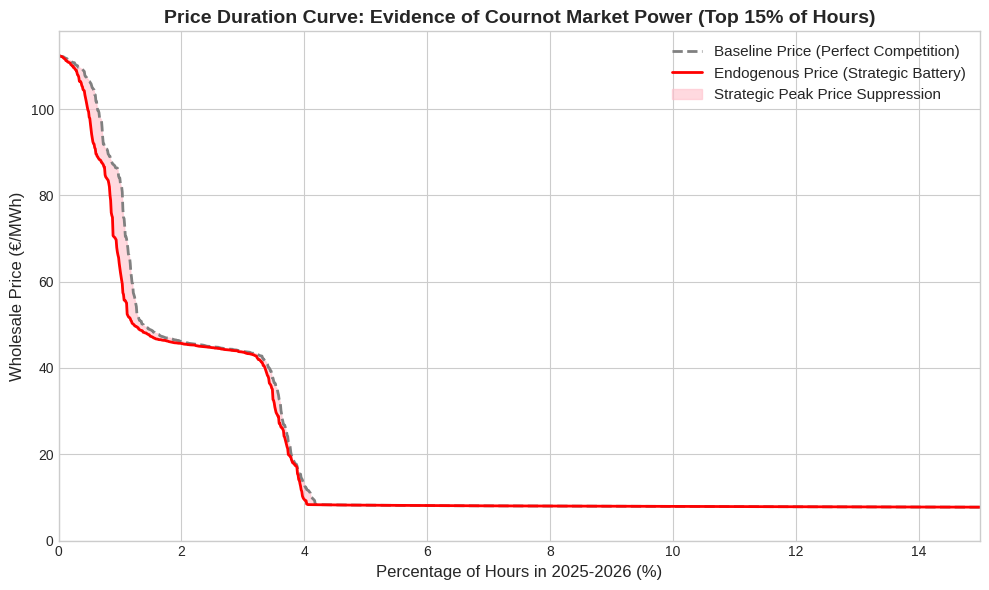

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


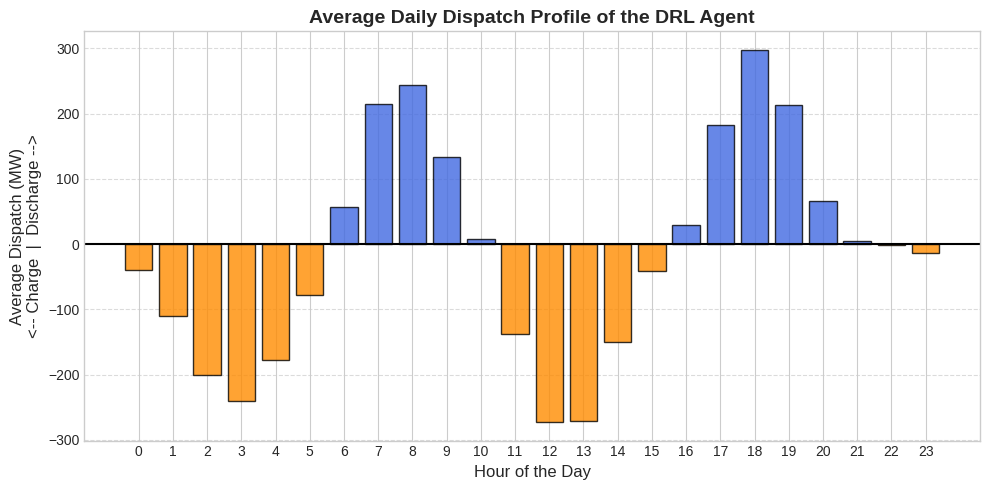

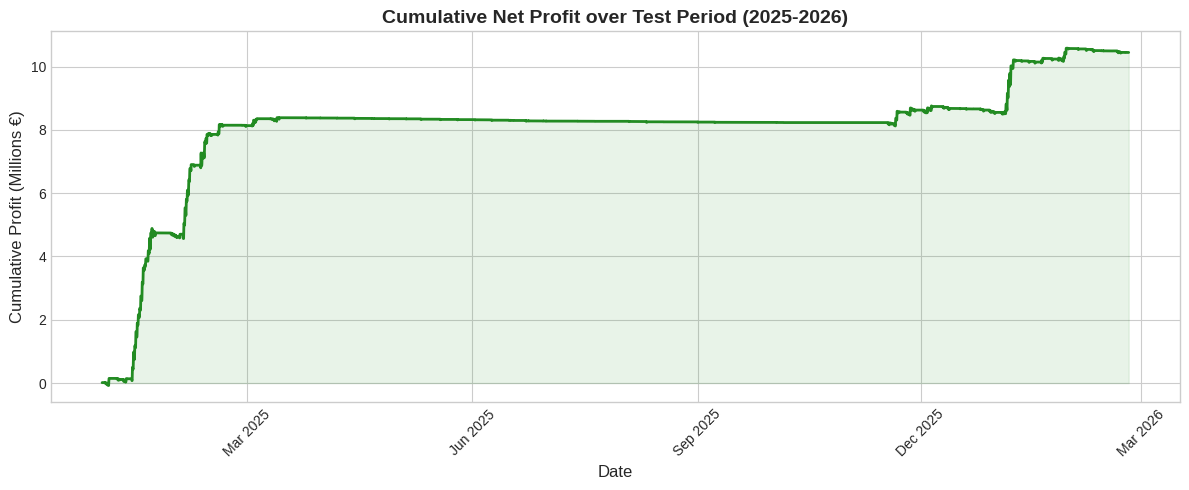

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:

# Load the Evaluation Data
df = pd.read_csv('/content/drive/MyDrive/Battery_RL_Model/Final_Results_2025_2026.csv',
                 parse_dates=['Datetime'], index_col='Datetime')

# Calculate Net Profit per hour
df['Net_Profit_EUR'] = (df['Endogenous_Price_EUR'] * df['Dispatch_MW']) - df['Degradation_Cost_EUR']

# Set global plot style
plt.style.use('seaborn-v0_8-whitegrid')

# ==============================================================================
# PLOT 1: THE PRICE DURATION CURVE (Zoomed on the top 15% of hours)
# This visually proves the 6.47% Cournot Peak Suppression.
# ==============================================================================
sorted_baseline = np.sort(df['Baseline_Price_EUR'])[::-1]
sorted_endogenous = np.sort(df['Endogenous_Price_EUR'])[::-1]
x_pct = np.linspace(0, 100, len(df))

plt.figure(figsize=(10, 6))
plt.plot(x_pct, sorted_baseline, label='Baseline Price (Perfect Competition)', color='gray', linestyle='--', linewidth=2)
plt.plot(x_pct, sorted_endogenous, label='Endogenous Price (Strategic Battery)', color='red', linewidth=2)
plt.fill_between(x_pct, sorted_baseline, sorted_endogenous,
                 where=(sorted_baseline > sorted_endogenous),
                 color='pink', alpha=0.6, label='Strategic Peak Price Suppression')

plt.xlim(0, 15) # Zoom in on the top 15% most expensive hours
plt.ylim(bottom=max(0, sorted_endogenous[int(len(df)*0.15)] - 10))
plt.title('Price Duration Curve: Evidence of Cournot Market Power (Top 15% of Hours)', fontsize=14, fontweight='bold')
plt.xlabel('Percentage of Hours in 2025-2026 (%)', fontsize=12)
plt.ylabel('Wholesale Price (€/MWh)', fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# ==============================================================================
# PLOT 2: AVERAGE DAILY DISPATCH PROFILE
# Shows exactly what the battery learned to do during an average 24-hour cycle.
# ==============================================================================
df['Hour'] = df.index.hour
daily_profile = df.groupby('Hour')['Dispatch_MW'].mean()

plt.figure(figsize=(10, 5))
colors = ['royalblue' if val > 0 else 'darkorange' for val in daily_profile.values]
plt.bar(daily_profile.index, daily_profile.values, color=colors, edgecolor='black', alpha=0.8)
plt.axhline(0, color='black', linewidth=1.5)

plt.title('Average Daily Dispatch Profile of the DRL Agent', fontsize=14, fontweight='bold')
plt.xlabel('Hour of the Day', fontsize=12)
plt.ylabel('Average Dispatch (MW)\n<-- Charge  |  Discharge -->', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# ==============================================================================
# PLOT 3: CUMULATIVE NET PROFIT OVER TIME
# Shows how the 10.4 Million EUR was accumulated, highlighting seasonal volatility.
# ==============================================================================
df['Cumulative_Profit_Million'] = df['Net_Profit_EUR'].cumsum() / 1e6

plt.figure(figsize=(12, 5))
plt.plot(df.index, df['Cumulative_Profit_Million'], color='forestgreen', linewidth=2)

plt.title('Cumulative Net Profit over Test Period (2025-2026)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Cumulative Profit (Millions €)', fontsize=12)

# Format x-axis for dates
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.xticks(rotation=45)

plt.fill_between(df.index, df['Cumulative_Profit_Million'], color='forestgreen', alpha=0.1)
plt.tight_layout()
plt.show()